# Phase 3 - Machine Learning Modelling

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import json
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn import metrics
from xgboost import XGBClassifier


## Defining the problem
**Business Purpose:**  
Predicting the probability that somebody will experience financial distress in the next two years.

**Target** `SeriousDlqin2yrs` - Person experienced 90 days past due delinquency or worse: type: Y/N

In [2]:
# Step 1 Load the dataset
df = pd.read_csv("../outputs/model_table.csv")
print(df.shape)
df.head()

(150000, 14)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,total-number_of_lates,log_transformed-montly-income
0,1,1,0.766127,45.0,2,0.802982,9120.0,13,0,6,0,2.0,2,9.118335
1,2,0,0.957151,40.0,0,0.121876,2600.0,4,0,0,0,1.0,0,7.863651
2,3,0,0.658180,38.0,1,0.085113,3042.0,2,1,0,0,0.0,2,8.020599
3,4,0,0.233810,30.0,0,0.036050,3300.0,5,0,0,0,0.0,0,8.101981
4,5,0,0.907239,49.0,1,0.024926,63588.0,7,0,1,0,0.0,1,11.060196


In [3]:
# step 2) Select credit score features
score_target = "SeriousDlqin2yrs"

score_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]
engineered_features = ["total-number_of_lates", "log_transformed-montly-income"]
score_df = df[score_features + engineered_features + [score_target]].copy()
print("Credit scoring dataset shape", score_df.shape)
score_df.head()

Credit scoring dataset shape (150000, 13)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,total-number_of_lates,log_transformed-montly-income,SeriousDlqin2yrs
0,0.766127,45.0,2,0.802982,9120.0,13,0,6,0,2.0,2,9.118335,1
1,0.957151,40.0,0,0.121876,2600.0,4,0,0,0,1.0,0,7.863651,0
2,0.658180,38.0,1,0.085113,3042.0,2,1,0,0,0.0,2,8.020599,0
3,0.233810,30.0,0,0.036050,3300.0,5,0,0,0,0.0,0,8.101981,0
4,0.907239,49.0,1,0.024926,63588.0,7,0,1,0,0.0,1,11.060196,0


In [4]:
# Step 3) Train/test split
split_idx = int(len(score_df)*0.8)

score_train = score_df.iloc[:split_idx].copy()
score_test = score_df.iloc[split_idx:].copy()

X_train_score = score_train[score_features + engineered_features]
X_test_score = score_test[score_features + engineered_features]

y_train_score = score_train[score_target]
y_test_score = score_test[score_target]

print("Train shape: ", X_train_score.shape)
print("Test shape: ", X_test_score.shape)

Train shape:  (120000, 12)
Test shape:  (30000, 12)


## Preprocessing Pipeline
**Numeric** → SimpleImputer (median strategy)

Combined using ColumnTransformer.
This entire pipeline gets saved with the model — 
no separate preprocessing step at inference time.

In [5]:
# Step 4) Preprocessing Pipeline

numeric_features = [
    "RevolvingUtilizationOfUnsecuredLines", "age",
    "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio",
    "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate", "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfDependents",
    "total-number_of_lates", "log_transformed-montly-income"
]

numeric_transformer = Pipeline(steps=[
    ('imputer',  SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

score_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
], remainder='drop')

print("Preprocessing is ready!")

Preprocessing is ready!


## Baseline Model: Logistic Regression

We start with basic regression model. `class_weight='balanced` helps us to deal with class imbalance, also we'll use roc-auc metrics for more precise evaluation

Additionally, we will use Stratified K-Fold cross-validation

In [6]:
# Stratified K-Fold cross-validation
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

# metrics
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

In [7]:
# Step 5) Logistic Regression

# Define model
score_baseline_model = Pipeline(steps=[
    ("preprocessor", score_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# metrics
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

scores = cross_validate(
    score_baseline_model, 
    X_train_score, 
    y_train_score, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1
)

print(f"ROC-AUC per fold: {scores['test_roc_auc']}")
print(f"Mean ROC-AUC:, {scores['test_roc_auc'].mean()}")
print(f"ROC-AUC std:, {scores['test_roc_auc'].std()}")

print("AP per fold:", scores["test_average_precision"])
print("Mean AP:", scores["test_average_precision"].mean())
print("AP std:", scores["test_average_precision"].std())

ROC-AUC per fold: [0.79758137 0.78772001 0.78831251 0.77816593 0.78702214]
Mean ROC-AUC:, 0.7877603904988753
ROC-AUC std:, 0.0061539712130950245
AP per fold: [0.32662316 0.30476997 0.30420036 0.28357962 0.30960719]
Mean AP: 0.305756061033294
AP std: 0.013751029310504944


## Advanced Model: Random Forest
Random Forest captures non-linear relationships between features

Logistic Regression finds linear relationship, but relationship between delinquency and other features might not be linear

In [8]:
# Step 6) Random Forest

score_rf_model = Pipeline(steps=[
    ("preprocessor", score_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, 
        max_depth=8, 
        min_samples_split=10, 
        class_weight='balanced_subsample', 
        random_state=42
    ))
])

scores_rf = cross_validate(
    score_rf_model, 
    X_train_score, 
    y_train_score, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1
)

print(f"ROC-AUC per fold: {scores_rf['test_roc_auc']}")
print(f"Mean ROC-AUC:, {scores_rf['test_roc_auc'].mean()}")
print(f"ROC-AUC std:, {scores_rf['test_roc_auc'].std()}")

print("AP per fold:", scores_rf["test_average_precision"])
print("Mean AP:", scores_rf["test_average_precision"].mean())
print("AP std:", scores_rf["test_average_precision"].std())

ROC-AUC per fold: [0.86653642 0.86427479 0.85970994 0.85147432 0.861458  ]
Mean ROC-AUC:, 0.8606906930511087
ROC-AUC std:, 0.0051674042560225135
AP per fold: [0.40591406 0.38214707 0.37975397 0.35875262 0.39627364]
Mean AP: 0.3845682730371687
AP std: 0.01605083106015484


In [9]:
def plot_roc_curve(X_train, X_test, y_train, y_test, model, model_name: str):
    # Fit the model
    model.fit(X_train, y_train)

    # Predict the probabilities for the positive class
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)

    # Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    # Plot the ROC curve
    plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle='--', label=f"{model_name} Baseline")
    plt.ylabel("True Positive Rate")
    plt.xlabel("False Positive Rate")
    plt.title('ROC Curve - Random Forest')
    plt.legend()
    plt.show()

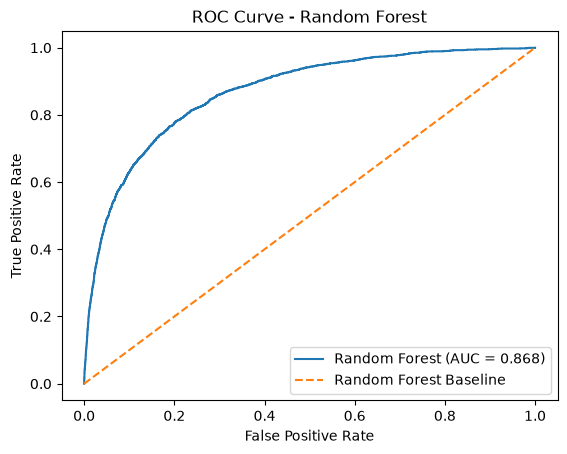

In [10]:
plot_roc_curve(
    X_train_score, 
    X_test_score, 
    y_train_score, 
    y_test_score, 
    score_rf_model,
    "Random Forest"
)

## XGBoost

XGBoost uses **gradient boosting** — builds trees sequentially,
each correcting the errors of the previous one.

Why XGBoost here:
   - Handles mixed numeric + categorical features well
    - Built-in regularisation prevents overfitting
    - Typically outperforms Random Forest on structured tabular data

In [11]:
# Step 7) XGBoost Model
score_xgb_model = Pipeline(steps=[
    ("preprocessor", score_preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic", 
        num_classes=2, 
        n_estimators=600, 
        max_depth=8, 
        learning_rate=0.005, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        random_state=42, 
        verbosity=0
    ))
])


scores_xgb = cross_validate(
    score_xgb_model, 
    X_train_score, 
    y_train_score, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1
)

print(f"ROC-AUC per fold: {scores_xgb['test_roc_auc']}")
print(f"Mean ROC-AUC:, {scores_xgb['test_roc_auc'].mean()}")
print(f"ROC-AUC std:, {scores_xgb['test_roc_auc'].std()}")

print("AP per fold:", scores_xgb["test_average_precision"])
print("Mean AP:", scores_xgb["test_average_precision"].mean())
print("AP std:", scores_xgb["test_average_precision"].std())

ROC-AUC per fold: [0.87140326 0.86814653 0.86475418 0.85459147 0.86278498]
Mean ROC-AUC:, 0.8643360833987058
ROC-AUC std:, 0.005692149118242728
AP per fold: [0.42294632 0.39879004 0.39912159 0.3682575  0.40960912]
Mean AP: 0.3997449150193011
AP std: 0.018046415720064945


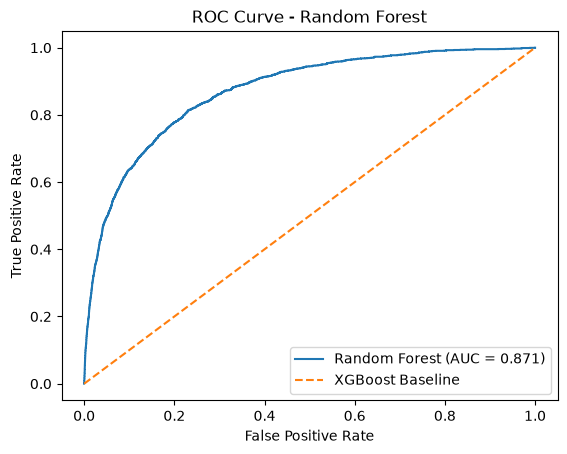

In [12]:
plot_roc_curve(X_train_score, X_test_score, y_train_score, y_test_score, score_xgb_model, model_name="XGBoost")

In [13]:
# Get best model by roc-auc score
print("="*45)
print("Credit Scoring Comparison")
print("="*45)
print(f"Logistic Regression: {scores['test_roc_auc'].mean():.4f}")
print(f"Random Forest: {scores_rf['test_roc_auc'].mean():.4f}")
print(f"XGBoost: {scores_xgb['test_roc_auc'].mean():.4f}")
print()
models = {
    "Logistic Regression": scores['test_roc_auc'].mean(),
    "Random Forest": scores_rf['test_roc_auc'].mean(),
    "XGBoost": scores_xgb['test_roc_auc'].mean()
}
best_model = max(models, key=models.get)
print(f"Best model -> {best_model} -> {models[best_model]:.4f}")

Credit Scoring Comparison
Logistic Regression: 0.7878
Random Forest: 0.8607
XGBoost: 0.8643

Best model -> XGBoost -> 0.8643


In [14]:
# Get best model by AP(Average Precision)
print("="*45)
print("Credit Scoring Comparison")
print("="*45)
print(f"Logistic Regression: {scores["test_average_precision"].mean():.4f}")
print(f"Random Forest: {scores_rf["test_average_precision"].mean():.4f}")
print(f"XGBoost: {scores_xgb["test_average_precision"].mean():.4f}")
print()
models = {
    "Logistic Regression": scores["test_average_precision"].mean(),
    "Random Forest": scores_rf["test_average_precision"].mean(),
    "XGBoost": scores_xgb["test_average_precision"].mean()
}
best_model = max(models, key=models.get)
print(f"Best model -> {best_model} -> {models[best_model]:.4f}")

Credit Scoring Comparison
Logistic Regression: 0.3058
Random Forest: 0.3846
XGBoost: 0.3997

Best model -> XGBoost -> 0.3997


## Hyperparameter Optimization

Process determines the set of hyperparameters that give best model performance. As a tool, we'll use `Optuna` open-source Python libary.

In [15]:
def objective(trial):
    # Define parameters
    params = {
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,

    "n_estimators": trial.suggest_int(
        "n_estimators", 300, 800, step=100
    ),

    "max_depth": trial.suggest_int(
        "max_depth", 3, 8
    ),

    "learning_rate": trial.suggest_float(
        "learning_rate", 0.01, 0.2, log=True
    ),

    "subsample": trial.suggest_float(
        "subsample", 0.5, 1.0
    ),

    "colsample_bytree": trial.suggest_float(
        "colsample_bytree", 0.6, 1.0
    ),

    "reg_alpha": trial.suggest_float(
        "reg_alpha", 0.5, 10.0, log=True
    ),

    "reg_lambda": trial.suggest_float(
        "reg_lambda", 0.5, 15.0, log=True
    ),

    "scale_pos_weight": trial.suggest_float(
        "scale_pos_weight", 1.0, 15.0
    )
}

    xgb_model = XGBClassifier(**params)

    scores = cross_validate(
        xgb_model, 
        X_train_score, 
        y_train_score, 
        cv=cv, 
        scoring=scoring, 
        n_jobs=1
    )

    print(
        f"ROC-AUC: {scores['test_roc_auc'].mean():.4f}, "
        f"AP: {scores['test_average_precision'].mean():.4f}"
    )

    return scores['test_average_precision'].mean()

In [16]:
# Run optimization

study = optuna.create_study(
    direction="maximize",
    study_name="credit_risk_xgboost",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective, 
    n_trials=30, 
    show_progress_bar=True
)

print("Best hyperparameters:", study.best_params)
print("Best value:", study.best_value)

[I 2026-10-18 07:58:59,331] A new study created in memory with name: credit_risk_xgboost


  0%|          | 0/30 [00:00<?, ?it/s]

ROC-AUC: 0.8296, AP: 0.3390
[I 2026-10-18 07:59:25,518] Trial 0 finished with value: 0.3389998940183235 and parameters: {'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.08960785365368121, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.6624074561769746, 'reg_alpha': 0.7978542347074177, 'reg_lambda': 0.609209325111088, 'scale_pos_weight': 13.126466040849092}. Best is trial 0 with value: 0.3389998940183235.
ROC-AUC: 0.8633, AP: 0.3967
[I 2026-10-18 07:59:52,557] Trial 1 finished with value: 0.39668876260415786 and parameters: {'n_estimators': 600, 'max_depth': 7, 'learning_rate': 0.010636066512540286, 'subsample': 0.9849549260809971, 'colsample_bytree': 0.9329770563201687, 'reg_alpha': 0.9445600138094694, 'reg_lambda': 0.9279990423245288, 'scale_pos_weight': 3.5676631379480734}. Best is trial 1 with value: 0.39668876260415786.
ROC-AUC: 0.8612, AP: 0.3948
[I 2026-10-18 08:00:10,895] Trial 2 finished with value: 0.39476803355121365 and parameters: {'n_estimators': 400, 'max_

In [24]:
# Define XGBoost with best parameters
best_xgb_model = Pipeline(steps=[
    ("preprocessing", score_preprocessor),
    ("model", XGBClassifier(
        objective='binary:logistic', 
        n_estimators=400,
        max_depth=6,
        learning_rate=0.014831660073622589,
        subsample=0.815584046804639,
        colsample_bytree=0.763165386967939,
        reg_alpha=8.750244277935877,
        reg_lamda=7.195684092208847,
        scale_pos_weight=1.8630641212756873))
])

# Train the model
best_xgb_model.fit(X_train_score, y_train_score)

# Predict
xgb_pred = best_xgb_model.predict_proba(X_test_score)[:, 1]

# Evaluate
print(f"ROC-AUC in test dataset: {roc_auc_score(y_test_score, xgb_pred)}")
print(f"Average Precision in test dataset: {average_precision_score(y_test_score, xgb_pred)}")

ROC-AUC in test dataset: 0.8721784970875396
Average Precision in test dataset: 0.4143803315948079


## Save Model Artifacts

Save model using joblib.
At inference time — FastAPI loads these files at startup.
No retraining needed per request.

In [25]:
joblib.dump(best_xgb_model, "../models/score_model.joblib")
print("Model saved:")
print("../models/score_model.joblib")

Model saved:
../models/score_model.joblib


## Save Feature Schema
The feature scheman tells FASTAPI:
- Which feature to expect requested for payload
- Which column is target

In [27]:
feature_schema = {
    "score_model_features": score_features + engineered_features,
    "score_target": score_target,
    "split_strategy": "K-Fold cross-validation"
}

with open("../outputs/feature_schema.json", "w") as f:
    json.dump(feature_schema, f, indent=4)

print("Feature schema saved!")
print(" -> ../outputs/feature_schema.json")

Feature schema saved!
 -> ../outputs/feature_schema.json
